In [ ]:
import pandas as pd
import numpy as np
!pip install cleantext evaluate
from cleantext import clean
import re
from transformers import XLNetTokenizer, XLNetForSequenceClassification, TrainingArguments, Trainer, pipeline
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import datasets
import evaluate
import random

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [evaluate]


## Preprocess our data

In [9]:
data_train = pd.read_csv('emotion-labels-train.csv')
data_test = pd.read_csv('emotion-labels-test.csv')
data_val = pd.read_csv('emotion-labels-val.csv')

In [10]:
data_train.head()

,text,label
0,Just got back from seeing @GaryDelaney in Burs...,joy
1,Oh dear an evening of absolute hilarity I don'...,joy
2,Been waiting all week for this game ❤️❤️❤️ #ch...,joy
3,"@gardiner_love : Thank you so much, Gloria! Yo...",joy
4,I feel so blessed to work with the family that...,joy


In [11]:
data = pd.concat([data_train, data_test, data_val], ignore_index=True)

In [16]:
data['text_clean'] = data['text'].apply(lambda x: clean(x))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [17]:
data['text_clean'] = data['text_clean'].apply(lambda x: re.sub('@[^\s]+', '', x))

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_566/149597858.py:1: SyntaxWarning: invalid escape sequence '\s'
  data['text_clean'] = data['text_clean'].apply(lambda x: re.sub('@[^\s]+', '', x))


In [18]:
data.head(20)

,text,label,text_clean
0,Just got back from seeing @GaryDelaney in Burs...,joy,got back see garydelaney burslem amaz face sti...
1,Oh dear an evening of absolute hilarity I don'...,joy,oh dear even absolut hilar dont think laugh mu...
2,Been waiting all week for this game ❤️❤️❤️ #ch...,joy,wait week game ❤️❤️❤️ cheer friday ❤️
3,"@gardiner_love : Thank you so much, Gloria! Yo...",joy,gardinerlov thank much gloria your sweet thoug...
4,I feel so blessed to work with the family that...,joy,feel bless work famili nanni ❤️ noth love amp ...
5,"Today I reached 1000 subscribers on YT!! , #go...",joy,today reach subscrib yt goodday thank
6,"@Singaholic121 Good morning, love! Happy first...",joy,singahol good morn love happi first day fall l...
7,#BridgetJonesBaby is the best thing I've seen ...,joy,bridgetjonesbabi best thing ive seen age funni...
8,Just got back from seeing @GaryDelaney in Burs...,joy,got back see garydelaney burslem amaz face sti...
9,@IndyMN I thought the holidays could not get a...,joy,indymn thought holiday could get cheer met the...


<Axes: xlabel='label'>

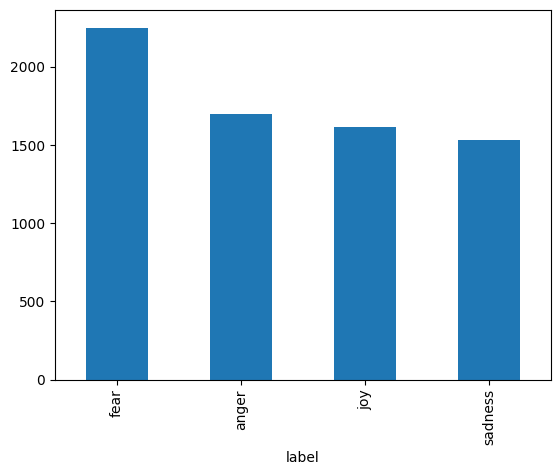

In [19]:
data['label'].value_counts().plot(kind="bar")

In [20]:
g = data.groupby('label')
data = pd.DataFrame(g.apply(lambda x: x.sample(g.size().min()).reset_index(drop=True)))

/tmp/ipykernel_566/2135407547.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data = pd.DataFrame(g.apply(lambda x: x.sample(g.size().min()).reset_index(drop=True)))


<Axes: xlabel='label'>

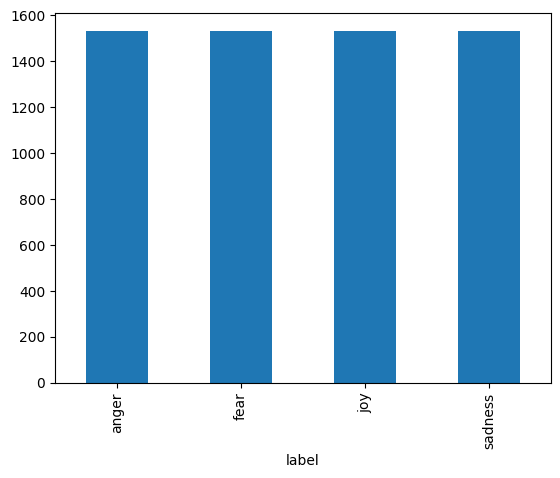

In [21]:
data['label'].value_counts().plot(kind="bar")

In [22]:
data['label_int'] = LabelEncoder().fit_transform(data['label'])

In [23]:
NUM_LABELS = 4

In [24]:
train_split, test_split = train_test_split(data, train_size = 0.8)
train_split, val_split = train_test_split(train_split, train_size = 0.9)

In [25]:
print(len(train_split))
print(len(test_split))
print(len(val_split))

4414
1227
491


In [26]:
train_df = pd.DataFrame({
    "label": train_split.label_int.values,
    "text": train_split.text_clean.values
})

test_df = pd.DataFrame({
    "label": test_split.label_int.values,
    "text": test_split.text_clean.values
})

In [27]:
train_df = datasets.Dataset.from_dict(train_df)
test_df = datasets.Dataset.from_dict(test_df)

In [28]:
dataset_dict = datasets.DatasetDict({"train":train_df, "test":test_df})

In [29]:
dataset_dict

DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 4414
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 1227
    })
})

## Create embeddings

In [30]:
tokenizer = XLNetTokenizer.from_pretrained("xlnet-base-cased")

spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

In [31]:
def tokenize_function(examples):
    return tokenizer(examples["text"], padding = "max_length", max_length = 128, truncation=True)

In [32]:
tokenized_datasets = dataset_dict.map(tokenize_function, batched=True)

Map:   0%|          | 0/4414 [00:00<?, ? examples/s]

Map:   0%|          | 0/1227 [00:00<?, ? examples/s]

In [35]:
tokenized_datasets

DatasetDict({
    train: Dataset({
        features: ['label', 'text', 'input_ids', 'attention_mask'],
        num_rows: 4414
    })
    test: Dataset({
        features: ['label', 'text', 'input_ids', 'attention_mask'],
        num_rows: 1227
    })
})

In [36]:
print(tokenized_datasets['train']['text'][0])

maxinutrit order parcel aw customercar dpduk tri view call card onlin black imag noshow


In [37]:
print(tokenized_datasets['train']['input_ids'][0])

[5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 17, 8467, 153, 2015, 8707, 374, 16388, 17, 3806, 2211, 2098, 17, 66, 450, 66, 2390, 8265, 985, 547, 1343, 31, 1554, 710, 17, 150, 7318, 116, 8676, 4, 3]


In [38]:
tokenizer.decode(5)

'<pad>'

In [40]:
print("Available keys in dataset:", tokenized_datasets['train'].features.keys())

Available keys in dataset: dict_keys(['label', 'text', 'input_ids', 'attention_mask'])


In [41]:
print(tokenized_datasets['train']['attention_mask'][0])

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [42]:
small_train_dataset = tokenized_datasets["train"].shuffle(seed=42).select(range(100))
small_eval_dataset = tokenized_datasets["test"].shuffle(seed=42).select(range(100))

## Fine tune our model

In [43]:
model = XLNetForSequenceClassification.from_pretrained('xlnet-base-cased',
                                                       num_labels=NUM_LABELS,
                                                       id2label={0: 'anger', 1: 'fear', 2: 'joy', 3: 'sadness'})

config.json:   0%|          | 0.00/760 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  467MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  467MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

[transformers] XLNetForSequenceClassification LOAD REPORT from: xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.weight                  | UNEXPECTED | 
lm_loss.bias                    | UNEXPECTED | 
logits_proj.weight              | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
sequence_summary.summary.bias   | MISSING    | 
logits_proj.bias                | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [44]:
metric = evaluate.load("accuracy")

In [45]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

In [46]:
training_args = TrainingArguments(output_dir="test_trainer", eval_strategy="epoch", num_train_epochs=3)

In [47]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=small_train_dataset,
    eval_dataset=small_eval_dataset,
    compute_metrics=compute_metrics)

In [48]:
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,1.469064,0.170000
2,No log,1.389658,0.270000
3,No log,1.459778,0.170000


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=39, training_loss=1.4045024774013422, metrics={'train_runtime': 663.6053, 'train_samples_per_second': 0.452, 'train_steps_per_second': 0.059, 'total_flos': 21366375321600.0, 'train_loss': 1.4045024774013422, 'epoch': 3.0})

## Evaluate model

In [49]:
trainer.evaluate()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy
No log,1.459778,3,0.170000


{'eval_loss': 1.4597784280776978, 'eval_accuracy': 0.17}

In [50]:
model.save_pretrained("fine_tuned_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [51]:
fine_tuned_model = XLNetForSequenceClassification.from_pretrained("fine_tuned_model")

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

In [52]:
clf = pipeline("text-classification", fine_tuned_model, tokenizer=tokenizer)

In [53]:
rand_int = random.randint(0, len(val_split))
print(val_split['text_clean'][rand_int])
answer = clf(val_split['text_clean'][rand_int], top_k=None)
print(answer)

/tmp/ipykernel_566/3116462782.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(val_split['text_clean'][rand_int])
/tmp/ipykernel_566/3116462782.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  answer = clf(val_split['text_clean'][rand_int], top_k=None)


childctweet sad peopl sick bore 😬😬😬
[{'label': 'sadness', 'score': 0.3243122100830078}, {'label': 'anger', 'score': 0.283611923456192}, {'label': 'fear', 'score': 0.20816823840141296}, {'label': 'joy', 'score': 0.18390755355358124}]
